# 09 · Avaliação da métrica v4 — Cover Shadow Value (CSV)

Fase 8d do CRISP-DM (D38). Reavalia a v4 (decomposição simétrica; cada linha pesada pela probabilidade de escolha, linhas até 35 m, interceção separada da dissuasão, Shapley entre defesas) com os critérios C1 a C8. Apresentam-se só números: a leitura de cada critério fica fora deste caderno.

- **C1/C2** · revisão de lances: lances preparados para a 4.ª ronda (secção 1).
- **C4** · estabilidade: ρ de Spearman por jogador dentro da posição e % da ameaça disponível negada, por variante e jogo (secção 2).
- **C5** · corpo vs bola, na v4 (secção 3).
- **C8** · poder preditivo do modelo de escolha, fora da amostra (secção 4).
- Descrição para o artigo (secção 5), reprodutibilidade (**C6**, secção 6) e nota sobre o **C3** (secção 7).

Convenções: a ameaça negada e o perigo disponível da v4 são xT esperado (`E(∅)`, `v = E(∅) − E(C)`); `% negada` = 100 · Σv / ΣE(∅). Os coeficientes do modelo de escolha de cada jogo vêm do ajuste no outro jogo (cross-fitting); nas variantes dos parâmetros mantêm-se os coeficientes da base, sem reajustar. O ρ por jogador junta os dois jogos e calcula-se dentro de cada posição (posições com pelo menos 4 jogadores; média ponderada pelo número de jogadores).
**Fundo (D39).** A 4.ª ronda (secção 1) e a secção 8 usam a v4 com o fundo; as secções 2 a 7 mantêm a v4 da D38 (sem fundo), que é a do artigo.


In [1]:
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from footy.ingest import skillcorner as sc
from footy.paths import PROJECTS, output_dir
from footy.viz.theme import apply_theme, load_brand

sys.path.insert(0, str(PROJECTS / "cover_shadow"))  # para importar o código do projeto
import analise_fundo as af
import avaliacao as av
import avaliacao_v4 as a4
import calcular_v4 as c4
import revisao_v4 as r4
from metrica import agregacao

pd.options.display.float_format = "{:.4f}".format
brand = load_brand()
apply_theme(brand)
FONTE = "SkillCorner Open Data (MIT)"
SAIDA = output_dir("cover_shadow")
JOGOS = list(sc.JOGOS_COM_POSE)
NOMES = {1925299: "Brisbane Roar – Perth Glory", 1996435: "Sydney FC – Adelaide United"}
JG = {j: r4.carregar_jogo(j) for j in JOGOS}  # tabela, defesas (parâmetros da v3), campo, nomes
V4 = {j: c4.ler_v4(j, "sem_fundo") for j in JOGOS}  # a v4 da D38 (secções 2 a 7); a do fundo (D39) é a V4F
V4F = {j: c4.ler_v4(j) for j in JOGOS}
MATCH = {j: JG[j]["match"] for j in JOGOS}
JOGADORES = {j: c4.jogadores_do_jogo(MATCH[j]) for j in JOGOS}
PRESENCA = {j: JG[j]["defesas"][["frame", "posse_id", "jogador"]] for j in JOGOS}
NUM = {"definicao": {"versao": "v4, decomposição simétrica (D38)", "jogos": JOGOS,
                     "limite_comprimento_m": 35.0, "conjuntos_de_coeficientes": a4.N_CONJUNTOS}}

## 1. Revisão de lances (C1/C2): 4.ª ronda

Com a v4 com fundo (D39, secção 8). Lances: os 8 da 3.ª ronda (W01–W08, para comparar) e os 3 momentos com a dissuasão (D) mais negativa de todos os momentos dos dois jogos, escolhidos de novo com o fundo (D01–D03, com posses distintas entre si e das da 3.ª ronda). Cada lance tem uma figura (valor de cada defesa na v4: interceção I, dissuasão D e total, em xT) e um clip de ~3 s com o mesmo desenho; a folha `revisao_lances_v4.xlsx` leva, no topo, a legenda («p = probabilidade de o passe chegar; s = probabilidade de o portador escolher esta linha, sem → com sombras; I = valor por cortar a linha; D = valor por fazer o portador mudar de escolha») e duas perguntas (ordem dos defesas por valor; divisão entre interceção e dissuasão), cada uma com resposta sim / em parte / não e comentário.

O índice dos lances guarda-se uma só vez (`outputs/cover_shadow/revisao_v4/indice_dos_lances.csv`) e a folha só se cria se não existir: reexecutar o caderno não os reescreve.

In [2]:
PASTA_V4 = SAIDA / "revisao_v4"
INDICE = PASTA_V4 / "indice_dos_lances.csv"
FOLHA_V4 = PROJECTS / "cover_shadow" / "revisao_lances_v4.xlsx"
PASTA_V4.mkdir(parents=True, exist_ok=True)
if not INDICE.exists():
    indice_v3 = pd.read_csv(SAIDA / "revisao_v3" / "indice_dos_lances.csv")
    r4.montar_indice(indice_v3, {j: V4F[j]["momentos"] for j in JOGOS}).to_csv(INDICE, index=False)
    print("Índice criado.")
else:
    print("Índice já existente (não é alterado).")
indice = pd.read_csv(INDICE)
indice["ficheiros"] = indice["nome"] + ".png + " + indice["nome"] + ".mp4"
for r in indice.itertuples():
    titulo = f"{JG[r.jogo]['titulo']} · {r.periodo}.ª parte · frame {r.frame}"
    if not (PASTA_V4 / f"{r.nome}.png").exists():
        r4.guardar_figura(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_V4, r.nome)
    if not (PASTA_V4 / f"{r.nome}.mp4").exists():
        r4.guardar_clip(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_V4, r.nome)
criada = r4.criar_folha_xlsx(indice.sort_values("lance")[["lance", "ficheiros"]], FOLHA_V4)
print("Folha criada em branco." if criada else "Folha já existente (não é alterada).")
print(f"{len(indice)} figuras e {len(indice)} clips em {PASTA_V4}")

Índice já existente (não é alterado).
Folha já existente (não é alterada).
11 figuras e 11 clips em outputs\cover_shadow\revisao_v4


Lance,Grupo,Jogo,Parte,Frame,Linhas,Defesas em C,E(∅),E(C),I,D,v
D01,dissuasao_mais_negativa,1996435,1,23728,5,5,0.162173,0.183806,0.011151,-0.032783,-0.021633
D02,dissuasao_mais_negativa,1996435,1,25338,8,5,0.077512,0.096984,0.010910,-0.030382,-0.019472
D03,dissuasao_mais_negativa,1996435,2,46832,6,5,0.151796,0.167772,0.012687,-0.028663,-0.015976
W01,ronda_3,1925299,1,14478,5,4,0.021803,0.000854,0.014139,0.006810,0.020949
W02,ronda_3,1925299,2,50612,9,5,0.025426,0.001545,0.015603,0.008278,0.023881
W03,ronda_3,1925299,2,57378,6,3,0.005371,0.000001,0.005354,0.000017,0.005370
W04,ronda_3,1996435,2,45252,5,4,0.096309,0.111889,0.000770,-0.016350,-0.015580
W05,ronda_3,1996435,1,13394,8,4,0.032339,0.000456,0.020349,0.011534,0.031883
W06,ronda_3,1925299,2,38118,7,2,0.000842,0.000829,0.000020,-0.000006,0.000013
W07,ronda_3,1996435,2,32452,6,3,0.000890,0.000889,0.000001,-0.000000,0.000001


lance,defesa,I,D,total
D01,P. Kikianis,0.000005,-0.000015,-0.000010
D01,J. Barnett,0.000879,-0.001213,-0.000334
D01,B. Vriends,0.003066,-0.004972,-0.001907
D01,F. Talladira,0.003588,-0.012136,-0.008548
D01,E. Alagich,0.003613,-0.014447,-0.010835
D02,J. Yull,0.000000,-0.000007,-0.000007
D02,Z. Clough,0.000000,-0.000009,-0.000008
D02,E. Alagich,0.000002,-0.000109,-0.000106
D02,J. Barnett,0.000003,-0.001357,-0.001354
D02,P. Kikianis,0.010905,-0.028901,-0.017996


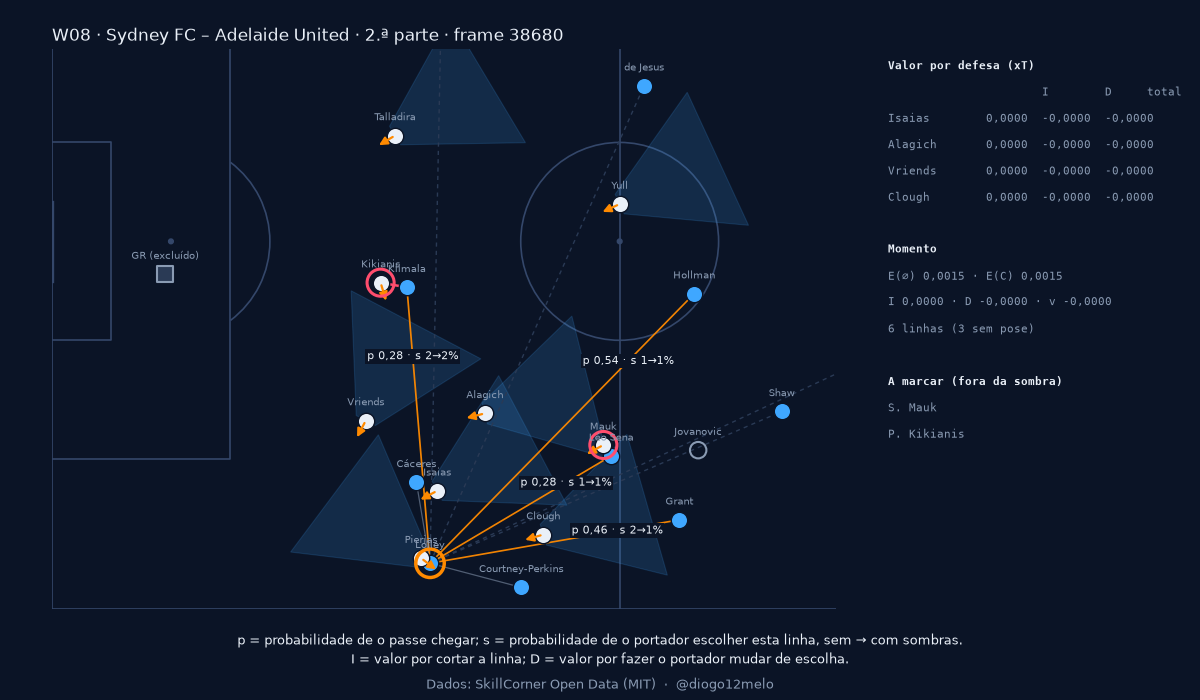

In [3]:
momentos_lances = []
for r in indice.itertuples():
    m = V4F[r.jogo]["momentos"].set_index("frame").loc[r.frame]
    momentos_lances.append({"Lance": r.lance, "Grupo": r.grupo, "Jogo": str(r.jogo), "Parte": r.periodo, "Frame": r.frame,
                            "Linhas": int(m["n_linhas"]), "Defesas em C": int(m["n_defesas"]), "E(∅)": m["E0"], "E(C)": m["EC"],
                            "I": m["I"], "D": m["D"], "v": m["v"]})
tabela_lances = pd.DataFrame(momentos_lances).sort_values("Lance")
display(tabela_lances.style.hide(axis="index"))
por_defesa = []
for r in indice.sort_values("lance").itertuples():
    d = r4.dados_do_frame_v4(JG[r.jogo], r.frame)
    v = r4.valores_por_defesa(d)
    por_defesa.append(v.assign(lance=r.lance, defesa=[JG[r.jogo]["nomes"][j] for j in v.index]))
por_defesa = pd.concat(por_defesa)[["lance", "defesa", "I", "D", "total"]].reset_index(drop=True)
display(por_defesa.style.hide(axis="index"))
NUM["revisao_4a_ronda"] = {"lances": tabela_lances.to_dict(orient="records"), "por_defesa": por_defesa.to_dict(orient="records")}
display(Image(PASTA_V4 / f"{indice.sort_values('lance').iloc[-1]['nome']}.png"))

## 2. Estabilidade (C4)

Variantes: as da v3 (abertura e comprimento do cone, largura junto ao corpo, tempo de reação, velocidade da bola, incerteza do tempo, limiares da marcação — entrada a 3 e 5 m e tempo mínimo — e o bloqueio pelo corpo com raio fixo de 0 / 0,5 / 0,7 / 1 / 1,5 m), mais o limite de comprimento das linhas (30 e 40 m; a base usa 35 m), o ajuste dos coeficientes com os dois jogos contra o cross-fitting e a incerteza dos coeficientes (50 conjuntos tirados da distribuição normal estimada no ajuste do outro jogo, média = coeficientes, covariância = inverso do Hessiano).

Por variante: ρ de Spearman face à base por jogador dentro da posição (média ponderada e mínimo) e % da ameaça disponível negada, por jogo. As colunas `v3` repetem o cálculo na v3 (mesma variante, mesma base v3) para comparação.

In [4]:
def tabela_de_jogadores(nome, pasta_v3=False):
    partes, pct = [], {}
    for j in JOGOS:
        if pasta_v3:
            linhas, atribuicoes = av.ler_variante(j, nome, av.PASTA_AVALIACAO_V3)
            partes.append(av.negada_por_jogador(linhas, atribuicoes, PRESENCA[j], JOGADORES[j]).assign(jogo=j))
            pct[j] = av.pct_negada(linhas)
        else:
            r = a4.ler(j, nome)
            partes.append(a4.negada_por_jogador(r["momentos"], r["atribuicoes"], PRESENCA[j], JOGADORES[j]).assign(jogo=j))
            pct[j] = a4.pct_negada(r["momentos"])
    return pd.concat(partes, ignore_index=True), pct


VARIANTES = list(a4.variantes_v4())
J4, P4 = {}, {}
J3, P3 = {}, {}
for nome in VARIANTES:
    J4[nome], P4[nome] = tabela_de_jogadores(nome)
    if nome in av.variantes_v3():
        J3[nome], P3[nome] = tabela_de_jogadores(nome, pasta_v3=True)
resumo4 = a4.resumo_das_variantes(J4, P4)
resumo3 = a4.resumo_das_variantes(J3, P3)
c4_tabela = resumo4.merge(resumo3, on="variante", how="left", suffixes=("", "_v3"))
ordem = ["variante", "rho_media", "rho_min", *[f"pct_negada_{j}" for j in JOGOS],
         "rho_media_v3", "rho_min_v3", *[f"pct_negada_{j}_v3" for j in JOGOS]]
display(c4_tabela[ordem].rename(columns={"rho_media": "ρ média", "rho_min": "ρ mín.", "rho_media_v3": "ρ média v3",
                                         "rho_min_v3": "ρ mín. v3", **{f"pct_negada_{j}": f"% negada {j}" for j in JOGOS},
                                         **{f"pct_negada_{j}_v3": f"% negada {j} v3" for j in JOGOS}}).style.hide(axis="index"))
NUM["c4"] = {"variantes": c4_tabela[ordem].to_dict(orient="records"), "base_pct_negada": {str(j): v for j, v in P4["base"].items()}}

variante,ρ média,ρ mín.,% negada 1925299,% negada 1996435,ρ média v3,ρ mín. v3,% negada 1925299 v3,% negada 1996435 v3
base,1.000000,1.000000,43.676710,30.793304,1.000000,1.000000,46.909983,39.418756
raio_bloqueio_corpo=0,0.934456,0.800000,18.731033,14.029506,0.896137,0.700000,24.802012,22.177480
raio_bloqueio_corpo=0.5,0.975651,0.900000,34.530639,24.853364,0.984142,0.900000,40.826338,35.284567
raio_bloqueio_corpo=0.7,0.969227,0.900000,41.728601,29.381413,0.996406,0.976190,47.454072,39.480021
raio_bloqueio_corpo=1,0.986972,0.900000,47.779052,33.305548,0.997170,0.983333,54.057438,45.521901
raio_bloqueio_corpo=1.5,0.944340,0.800000,52.058289,39.396703,0.920171,0.200000,59.264306,51.382366
angulo_cone=45,0.997170,0.983333,43.076411,29.868930,1.000000,1.000000,45.781033,38.140835
angulo_cone=90,0.981132,0.900000,44.871829,32.725064,1.000000,1.000000,48.810479,41.870505
comprimento_cone=8,1.000000,1.000000,43.695274,30.769915,0.992812,0.952381,46.747658,38.891712
comprimento_cone=12,1.000000,1.000000,43.519062,30.826696,0.993576,0.976190,46.903032,39.580014


### 2.1 Coeficientes: dois jogos vs cross-fitting, e incerteza

`ambos` = coeficientes do M2 ajustados com os dois jogos (cada jogo avaliado também com dados seus); as 50 `inc` partem do ajuste no outro jogo e sorteiam os coeficientes da sua distribuição estimada. As linhas e as sombras são as mesmas da base; só muda a escolha.

In [5]:
def tabela_alternativa(nome):
    partes, pct = [], {}
    for j in JOGOS:
        r = a4.ler(j, "base")
        momentos = r["alt_momentos"].query("alt == @nome")
        atribuicoes = r["alt_atribuicoes"].query("alt == @nome")
        partes.append(a4.negada_por_jogador(momentos, atribuicoes, PRESENCA[j], JOGADORES[j], coluna="shapley").assign(jogo=j))
        pct[j] = a4.pct_negada(momentos)
    return pd.concat(partes, ignore_index=True), pct


ALT, PALT = {}, {}
for nome in a4.ALTERNATIVOS_DA_BASE:
    ALT[nome], PALT[nome] = tabela_alternativa(nome)
resumo_alt = a4.resumo_das_variantes({"base": J4["base"], **ALT}, {"base": P4["base"], **PALT}).query("variante != 'base'")
ambos = resumo_alt[resumo_alt["variante"] == "ambos"]
conjuntos = resumo_alt[resumo_alt["variante"] != "ambos"].set_index("variante")
display(Markdown("**Coeficientes ajustados com os dois jogos (`ambos`) vs cross-fitting (base)**"))
display(ambos.rename(columns={"rho_media": "ρ média", "rho_min": "ρ mín.", "n_posicoes": "posições"}).style.hide(axis="index"))
display(Markdown(f"**Incerteza dos coeficientes: {len(conjuntos)} conjuntos** (média, mínimo, máximo e percentis 2,5 e 97,5 de cada medida)"))
distribuicao = a4.distribuicao_das_alternativas(conjuntos[["rho_media", "rho_min", *[f"pct_negada_{j}" for j in JOGOS]]])
display(pd.DataFrame(distribuicao).T.rename(columns={"media": "média", "p2_5": "p2,5", "p97_5": "p97,5"}))
NUM["c4"]["ambos"] = ambos.drop(columns="variante").iloc[0].to_dict()
NUM["c4"]["incerteza_dos_coeficientes"] = {"conjuntos": len(conjuntos), "distribuicao": distribuicao}

**Coeficientes ajustados com os dois jogos (`ambos`) vs cross-fitting (base)**

variante,ρ média,ρ mín.,posições,pct_negada_1925299,pct_negada_1996435
ambos,0.990566,0.900000,9,42.881921,31.120236


**Incerteza dos coeficientes: 50 conjuntos** (média, mínimo, máximo e percentis 2,5 e 97,5 de cada medida)

,média,min,max,"p2,5","p97,5"
rho_media,0.9837,0.9560,1.0000,0.9643,1.0000
rho_min,0.9079,0.8000,1.0000,0.8000,1.0000
pct_negada_1925299,43.6626,35.9745,49.2072,36.4215,48.0862
pct_negada_1996435,30.9001,27.0690,34.2772,27.2745,33.8769


## 3. Corpo vs bola (C5) na v4

Versão `bola`: a sombra vira-se para a bola em todo o lado (defesas orientadas para o portador) e o modelo de escolha usa os coeficientes do M1 (sombra virada para a bola), ajustados no outro jogo; o resto é igual à base. Os defesas sem pose continuam sem orientação, por isso as duas versões avaliam as mesmas linhas.

In [6]:
tronco = {j: a4.ler(j, "base") for j in JOGOS}
bola = {j: a4.ler(j, "bola") for j in JOGOS}
mudam = {str(j): a4.linhas_que_mudam(tronco[j]["linhas"], bola[j]["linhas"]) for j in JOGOS}
mudam["total"] = a4.linhas_que_mudam(pd.concat([tronco[j]["linhas"].assign(frame=lambda t, j=j: t["frame"] + j * 10**7) for j in JOGOS]),
                                     pd.concat([bola[j]["linhas"].assign(frame=lambda t, j=j: t["frame"] + j * 10**7) for j in JOGOS]))
display(Markdown("**Linhas em que muda quem faz sombra** (linhas presentes nas duas versões)"))
display(pd.DataFrame(mudam).T.rename(columns={"linhas": "linhas", "linhas_que_mudam": "mudam", "pct_muda": "% mudam",
                                              "linhas_com_sombra_em_alguma": "com sombra em alguma",
                                              "pct_muda_entre_as_com_sombra": "% mudam (entre as com sombra)"}))
rho_bola = av.spearman_por_posicao(J4["base"], J4["bola"])
display(Markdown(f"**ρ de Spearman por jogador, tronco vs bola** · média ponderada {rho_bola['rho_media']:.4f} · mínimo por posição {rho_bola['rho_min']:.4f}"))
display(rho_bola["posicoes"].rename(columns={"posicao": "posição", "n": "n (jogadores)", "rho": "ρ"}).style.hide(axis="index"))
pct_c5 = pd.DataFrame({"tronco": P4["base"], "bola": P4["bola"]}).rename_axis("jogo")
display(Markdown("**% da ameaça disponível negada, tronco vs bola**"))
display(pct_c5)
NUM["c5"] = {"linhas_que_mudam": mudam, "rho_media": rho_bola["rho_media"], "rho_min": rho_bola["rho_min"],
             "rho_por_posicao": rho_bola["posicoes"].to_dict(orient="records"),
             "pct_negada": {str(j): {"tronco": P4["base"][j], "bola": P4["bola"][j]} for j in JOGOS}}

**Linhas em que muda quem faz sombra** (linhas presentes nas duas versões)

,linhas,mudam,% mudam,com sombra em alguma,% mudam (entre as com sombra)
1925299,63151.0000,23325.0000,36.9353,34972.0000,66.6962
1996435,57866.0000,21616.0000,37.3553,33065.0000,65.3743
total,121017.0000,44941.0000,37.1361,68037.0000,66.0538


**ρ de Spearman por jogador, tronco vs bola** · média ponderada 0.9483 · mínimo por posição 0.8000

posição,n (jogadores),ρ
AM,5,1.000000
CF,9,0.916667
LB,4,0.800000
LCB,5,0.900000
LW,8,0.976190
RB,5,0.900000
RCB,4,1.000000
RDM,5,1.000000
RW,8,1.000000


**% da ameaça disponível negada, tronco vs bola**

,tronco,bola
jogo,,
1925299,43.6767,44.7067
1996435,30.7933,37.3036


In [7]:
LANCES_C5 = (("C06", 1925299, 12660), ("C03", 1996435, 39646))
NUM["c5"]["lances"] = {}
for rotulo, jogo, frame in LANCES_C5:
    totais, defesas_lance = {}, {}
    for versao, d in (("tronco", tronco[jogo]), ("bola", bola[jogo])):
        m = d["momentos"].set_index("frame").loc[frame]
        totais[versao] = {"linhas": m["n_linhas"], "E(∅)": m["E0"], "E(C)": m["EC"], "I": m["I"], "D": m["D"], "v": m["v"]}
        a = d["atribuicoes"][d["atribuicoes"]["frame"] == frame].set_index("defesa")
        defesas_lance[versao] = a[["shapley_I", "shapley_D", "shapley"]].rename(
            columns={"shapley_I": f"I {versao}", "shapley_D": f"D {versao}", "shapley": f"total {versao}"})
    por_defesa_c5 = pd.concat(defesas_lance.values(), axis=1).fillna(0.0)
    por_defesa_c5.index = por_defesa_c5.index.map(JOGADORES[jogo].set_index("jogador")["nome"])
    display(Markdown(f"**{rotulo}** · jogo {jogo} · frame {frame}"))
    display(pd.DataFrame(totais))
    display(por_defesa_c5.sort_values("total tronco", ascending=False))
    NUM["c5"]["lances"][rotulo] = {"jogo": jogo, "frame": frame, "totais": totais,
                                   "por_defesa": por_defesa_c5.reset_index(names="defesa").to_dict(orient="records")}

**C06** · jogo 1925299 · frame 12660

,tronco,bola
linhas,7.0000,7.0000
E(∅),0.0029,0.0029
E(C),0.0026,0.0023
I,0.0002,0.0005
D,0.0001,0.0001
v,0.0003,0.0006


,I tronco,D tronco,total tronco,I bola,D bola,total bola
defesa,,,,,,
K. Jelacic,0.0002,0.0001,0.0003,0.0002,0.0001,0.0003
Walid Shour,0.0000,0.0000,0.0000,0.0002,0.0001,0.0003


**C03** · jogo 1996435 · frame 39646

,tronco,bola
linhas,8.0000,8.0000
E(∅),0.0018,0.0019
E(C),0.0012,0.0012
I,0.0004,0.0005
D,0.0002,0.0002
v,0.0006,0.0006


,I tronco,D tronco,total tronco,I bola,D bola,total bola
defesa,,,,,,
P. Klimala,0.0004,0.0002,0.0006,0.0005,0.0002,0.0006


## 4. Poder preditivo da escolha do passe (C8, resumo da fase 8b)

Do ficheiro `modelo_escolha.json` (fase 8b, `07_modelo_escolha.ipynb`): modelos M0 (variáveis da linha, sem sombra), M1 (+ sombra virada para a bola), M2 (+ sombra pelo tronco) e M3 (as duas sombras), ajustados num jogo e avaliados no outro, nos dois sentidos. Log-loss por passe (menor é melhor), top-1 e top-3; as diferenças são de log-loss por passe com IC 95 % por bootstrap sobre os passes (negativa = o primeiro modelo prevê melhor).

In [8]:
modelo_escolha = json.loads((SAIDA / "modelo_escolha.json").read_text(encoding="utf-8"))
c8 = a4.tabela_c8(modelo_escolha)
modelos = c8["modelos"]
modelos = modelos[modelos["modelo"].isin(["M0", "M1", "M2", "M3", "ao acaso"])]
display(Markdown("**Fora da amostra** (treino → teste)"))
display(modelos[["direcao", "modelo", "log_loss", "top1", "top3", "n_passes"]].style.hide(axis="index"))
display(Markdown("**Diferenças de log-loss por passe (IC 95 %)**"))
display(c8["diferencas"].style.hide(axis="index"))
display(Markdown("**Coeficientes do M3** (ajuste com os dois jogos: 1 414 passes)"))
display(c8["coeficientes_M3"])
NUM["c8"] = {"modelos": modelos.to_dict(orient="records"), "diferencas": c8["diferencas"].to_dict(orient="records"),
             "coeficientes_M3": c8["coeficientes_M3"].reset_index(names="variavel").to_dict(orient="records"),
             "passes_por_jogo": modelo_escolha["passes_por_jogo"]}

**Fora da amostra** (treino → teste)

direcao,modelo,log_loss,top1,top3,n_passes
1925299_para_1996435,M0,1.478241,0.403790,0.826531,686
1925299_para_1996435,M1,1.430056,0.434402,0.841108,686
1925299_para_1996435,M2,1.418546,0.435860,0.848397,686
1925299_para_1996435,M3,1.419836,0.434402,0.846939,686
1925299_para_1996435,ao acaso,1.987409,0.141005,0.423016,686
1996435_para_1925299,M0,1.534436,0.387363,0.789835,728
1996435_para_1925299,M1,1.482890,0.409341,0.800824,728
1996435_para_1925299,M2,1.480038,0.413462,0.803571,728
1996435_para_1925299,M3,1.479019,0.416209,0.804945,728
1996435_para_1925299,ao acaso,1.970763,0.144277,0.432144,728


**Diferenças de log-loss por passe (IC 95 %)**

direcao,comparacao,diferenca,ic95_inf,ic95_sup
1925299_para_1996435,M2 − M1,-0.011510,-0.024176,0.000655
1925299_para_1996435,M2 − M0,-0.059695,-0.083703,-0.035288
1925299_para_1996435,M3 − M2,0.001290,-0.003845,0.006622
1925299_para_1996435,M3 − M1,-0.010220,-0.018201,-0.002744
1925299_para_1996435,M3 − M0,-0.058405,-0.082720,-0.034134
1996435_para_1925299,M2 − M1,-0.002852,-0.011166,0.005300
1996435_para_1925299,M2 − M0,-0.054398,-0.074412,-0.032616
1996435_para_1925299,M3 − M2,-0.001020,-0.001937,-0.000105
1996435_para_1925299,M3 − M1,-0.003871,-0.011416,0.003562
1996435_para_1925299,M3 − M0,-0.055417,-0.075635,-0.033591


**Coeficientes do M3** (ajuste com os dois jogos: 1 414 passes)

,coef,erro_padrao,ic95_inf,ic95_sup,razao_de_chances
comprimento,-0.1491,0.0061,-0.1611,-0.1371,0.8615
avanco,0.0724,0.0043,0.0639,0.0808,1.0750
valor_xt,7.5647,2.5589,2.5493,12.5802,1928.9764
recetor_marcado,-0.5514,0.1135,-0.7737,-0.3290,0.5762
dist_adversario,0.1760,0.0093,0.1578,0.1942,1.1925
linha_sem_pose,-0.2785,0.1377,-0.5484,-0.0086,0.7569
sombra_bola,-0.4141,0.2624,-0.9284,0.1002,0.6610
sombra_tronco,-1.3617,0.2950,-1.9400,-0.7834,0.2562


## 5. Descrição para o artigo (v4)

### 5.1 % negada por fase defensiva e por terço

`% negada` = 100 · Σv / ΣE(∅) nos momentos (frames alinhados, 5 por segundo) com alguma linha avaliada; `momentos` = número desses momentos. A fase defensiva e o terço vêm das etiquetas da SkillCorner (D32): a fase é a do frame; o terço é o do início da posse.

In [9]:
CONTEXTO = {j: agregacao.contexto_dos_frames(JG[j]["tabela"], sc.ler_fases(j)) for j in JOGOS}
junto_m = pd.concat([V4[j]["momentos"].assign(jogo=j) for j in JOGOS], ignore_index=True)
junto_c = pd.concat([CONTEXTO[j].assign(jogo=j) for j in JOGOS], ignore_index=True)
NUM["descricao"] = {}
for por, rotulo in (("fase", "Fase defensiva"), ("terco", "Terço")):
    partes = []
    for jogo in [*JOGOS, "ambos"]:
        m = junto_m if jogo == "ambos" else junto_m[junto_m["jogo"] == jogo]
        c = junto_c if jogo == "ambos" else junto_c[junto_c["jogo"] == jogo]
        t = m.merge(c, on=["jogo", "frame"], how="left")  # os frames de jogos diferentes coincidem: junta-se por jogo
        t = t.rename(columns={"n_linhas": "n_avaliadas", "E0": "disponivel", "v": "negada"})
        g = t[t["n_avaliadas"] > 0].groupby(por, dropna=False).agg(momentos=("frame", "size"), disponivel=("disponivel", "sum"),
                                                                      negada=("negada", "sum")).reset_index()
        g["pct_negada"] = 100 * g["negada"] / g["disponivel"]
        partes.append(g.assign(jogo=str(jogo)))
    tabela = pd.concat(partes, ignore_index=True)
    display(Markdown(f"**{rotulo}**"))
    display(tabela.pivot(index=por, columns="jogo", values=["momentos", "pct_negada"]).sort_values(("momentos", "ambos"), ascending=False))
    NUM["descricao"][por] = tabela.to_dict(orient="records")

**Fase defensiva**

momentos                     pct_negada          \
jogo                    1925299   1996435     ambos    1925299 1996435   
fase                                                                     
medium_block          3392.0000 2920.0000 6312.0000    12.2225 16.4540   
low_block             2788.0000 2364.0000 5152.0000    46.1384 34.2141   
high_block            1648.0000 1939.0000 3587.0000     8.9149 14.2499   
chaotic                566.0000  409.0000  975.0000    58.4729 10.5127   
defending_quick_break  321.0000   79.0000  400.0000    55.3495 18.1585   
defending_transition    84.0000  247.0000  331.0000    17.8679 39.8498   
defending_set_play      94.0000  177.0000  271.0000    60.3269 39.9377   
defending_direct        18.0000   10.0000   28.0000     5.0066 29.4681   
NaN                      4.0000       NaN    4.0000   -16.4711     NaN   

                                
jogo                     ambos  
fase                            
medium_block           14.3241  
low_block              40.6139  
high_block             12.1114  
chaotic                40.9511  
defending_quick_break  50.4417  
defending_transition   37.4947  
defending_set_play     47.8676  
defending_direct       12.0686  
NaN                   -16.4711

**Terço**

momentos                     pct_negada                
jogo              1925299   1996435     ambos    1925299 1996435   ambos
terco                                                                   
middle_third    3872.0000 3317.0000 7189.0000    18.6072 18.5347 18.5694
defensive_third 2910.0000 2764.0000 5674.0000    10.2865 13.1894 11.7554
attacking_third 2133.0000 2064.0000 4197.0000    53.5989 37.4126 46.3915

### 5.2 Ameaça negada por comprimento da linha, v3 vs v4

Reparte-se a ameaça negada e a disponível pelo comprimento da linha de passe (0–10, 10–20, 20–30, 30–35 m; a v3 também tem linhas acima de 35 m, que a v4 exclui). Na v3 a ameaça disponível é a soma do `valor_xt` das linhas avaliadas; na v4 é `s₀ · x` (xT esperado) e a ameaça negada de cada linha é `x · (s₀ − s · p)`. As partes são percentagens do total de cada versão. Os dois jogos juntos.

In [10]:
def comprimentos_v3(jogo):
    linhas, _ = av.ler_variante(jogo, "base", av.PASTA_AVALIACAO_V3)
    linhas = linhas[~linhas["excluida"]]
    pos = JG[jogo]["tabela"][["frame", "jogador", "x", "y"]]
    portador = pos.rename(columns={"jogador": "portador", "x": "x0", "y": "y0"})
    recetor = pos.rename(columns={"jogador": "recetor", "x": "x1", "y": "y1"})
    t = linhas.merge(portador, on=["frame", "portador"], how="left").merge(recetor, on=["frame", "recetor"], how="left")
    return t.assign(comprimento=np.hypot(t["x1"] - t["x0"], t["y1"] - t["y0"]))


v3 = pd.concat([comprimentos_v3(j) for j in JOGOS], ignore_index=True)
v4 = pd.concat([V4[j]["linhas"] for j in JOGOS], ignore_index=True)
comp_v3 = a4.por_comprimento(v3["comprimento"], v3["ameaca_negada"], v3["valor_xt"])
comp_v4 = a4.por_comprimento(v4["comprimento"], v4["negada_linha"], v4["s0"] * v4["valor_xt"])
comparacao = pd.concat({"v3": comp_v3, "v4": comp_v4}, axis=1)
display(comparacao)
print(f"Linhas v3 sem comprimento calculado: {int(v3['comprimento'].isna().sum())}")
NUM["descricao"]["por_comprimento"] = {"v3": comp_v3.reset_index().to_dict(orient="records"),
                                       "v4": comp_v4.reset_index().to_dict(orient="records")}

v3                                                        v4  \
        linhas  negada disponivel pct_da_negada pct_do_disponivel linhas   
faixa                                                                      
0–10 m   13795 10.8858    35.0566        4.9670            6.9361  15276   
10–20 m  39658 61.7648   173.6247       28.1820           34.3523  45650   
20–30 m  31644 86.0374   185.5929       39.2570           36.7203  42406   
30–35 m  11208 28.7252    53.0350       13.1067           10.4932  17685   
> 35 m   23658 31.7510    58.1143       14.4873           11.4981      0   

                                                            
         negada disponivel pct_da_negada pct_do_disponivel  
faixa                                                       
0–10 m   3.5601    13.1854       10.8272           15.1037  
10–20 m 15.0483    44.2963       45.7659           50.7406  
20–30 m 12.1259    25.7017       36.8779           29.4408  
30–35 m  2.1468     4.1161        6.5290            4.7149  
> 35 m   0.0000     0.0000        0.0000            0.0000

Linhas v3 sem comprimento calculado: 0


### 5.3 Peso de I e de D no total, por posição

Soma, por posição, da ameaça negada por jogador (média por posse, soma por jogador) total, da parte de interceção (I) e da de dissuasão (D); `pct_I` e `pct_D` são o peso de cada parte no total da posição (somam 100).

In [11]:
partes = []
for j in JOGOS:
    t = c4.negada_por_jogador_v4(V4[j]["momentos"], V4[j]["atribuicoes"], PRESENCA[j], JOGADORES[j]).assign(jogo=j)
    partes.append(t)
jogadores_v4 = pd.concat(partes, ignore_index=True)
peso = a4.peso_de_I_e_D(jogadores_v4)
peso_jogo = {j: a4.peso_de_I_e_D(t) for j, t in jogadores_v4.groupby("jogo")}
display(Markdown("**Os dois jogos juntos**"))
display(peso)
for j in JOGOS:
    display(Markdown(f"**{j} ({NOMES[j]})**"))
    display(peso_jogo[j])
tot = jogadores_v4[["negada", "negada_I", "negada_D"]].sum()
print(f"Total (todas as posições): v {tot['negada']:.4f} · I {tot['negada_I']:.4f} ({100 * tot['negada_I'] / tot['negada']:.1f} %) · "
      f"D {tot['negada_D']:.4f} ({100 * tot['negada_D'] / tot['negada']:.1f} %)")
NUM["descricao"]["peso_I_D"] = {"ambos": peso.reset_index().to_dict(orient="records"),
                                **{str(j): t.reset_index().to_dict(orient="records") for j, t in peso_jogo.items()},
                                "total": {"v": tot["negada"], "I": tot["negada_I"], "D": tot["negada_D"]}}

**Os dois jogos juntos**

,jogadores,negada,negada_I,negada_D,pct_I,pct_D
posicao,,,,,,
AM,5,0.0658,0.0695,-0.0038,105.7424,-5.7424
CF,9,0.1584,0.1456,0.0129,91.8885,8.1115
LB,4,0.2435,0.2192,0.0243,90.0210,9.9790
LCB,5,0.4871,0.3533,0.1338,72.5329,27.4671
LDM,3,0.1741,0.1695,0.0046,97.3363,2.6637
LM,1,0.3693,0.2736,0.0958,74.0720,25.9280
LW,8,0.1056,0.1948,-0.0892,184.3902,-84.3902
RB,5,0.2522,0.2260,0.0262,89.6131,10.3869
RCB,4,0.4667,0.3276,0.1391,70.1928,29.8072


**1925299 (Brisbane Roar – Perth Glory)**

,jogadores,negada,negada_I,negada_D,pct_I,pct_D
posicao,,,,,,
AM,2,0.0043,0.0064,-0.0022,150.3675,-50.3675
CF,5,0.1079,0.1006,0.0073,93.2158,6.7842
LB,2,0.0891,0.0730,0.0162,81.8771,18.1229
LCB,3,0.2445,0.1768,0.0678,72.2788,27.7212
LDM,1,0.0145,0.0135,0.0010,93.1195,6.8805
LM,1,0.3693,0.2736,0.0958,74.0720,25.9280
LW,4,0.0698,0.1334,-0.0637,191.2758,-91.2758
RB,3,0.1592,0.1381,0.0211,86.7556,13.2444
RCB,2,0.2778,0.1960,0.0819,70.5376,29.4624


**1996435 (Sydney FC – Adelaide United)**

,jogadores,negada,negada_I,negada_D,pct_I,pct_D
posicao,,,,,,
AM,3,0.0615,0.0631,-0.0016,102.6338,-2.6338
CF,4,0.0505,0.0450,0.0055,89.0514,10.9486
LB,2,0.1543,0.1462,0.0081,94.7241,5.2759
LCB,2,0.2426,0.1766,0.0660,72.7891,27.2109
LDM,2,0.1596,0.1560,0.0036,97.7180,2.2820
LW,4,0.0359,0.0614,-0.0255,171.0051,-71.0051
RB,2,0.0930,0.0879,0.0051,94.5035,5.4965
RCB,2,0.1889,0.1316,0.0573,69.6856,30.3144
RDM,4,0.1830,0.1367,0.0462,74.7365,25.2635


Total (todas as posições): v 2.9590 · I 2.4813 (83.9 %) · D 0.4776 (16.1 %)


## 6. Reprodutibilidade (C6)

`reprodutibilidade_v4.py` guarda em memória as tabelas existentes (fase 3, escolhas de passe, `modelo_escolha.json` e v4), volta a correr cada passo a partir dos dados originais (`preparar_dados.py` → `escolha.py` → `modelo_escolha.py` → `calcular_v4.py`) e compara cada tabela nova com a anterior, coluna a coluna (numéricas até rtol 1e-9, atol 1e-12). Corre depois a suíte completa de testes. Resultado em `outputs/cover_shadow/reprodutibilidade_v4.json`.

In [12]:
ficheiro_c6 = SAIDA / "reprodutibilidade_v4.json"
if not ficheiro_c6.exists():
    print("Por calcular: uv run python projects/cover_shadow/reprodutibilidade_v4.py")
else:
    c6 = json.loads(ficheiro_c6.read_text(encoding="utf-8"))
    tabela_c6 = pd.DataFrame(c6["tabelas"]).T[["linhas_antes", "linhas_depois", "colunas_comuns", "iguais", "maior_diferenca_absoluta",
                                              "colunas_diferentes", "so_depois"]]
    display(tabela_c6)
    print(f"Valores diferentes no modelo_escolha.json: {len(c6['modelo_escolha_json_valores_diferentes'])}")
    print(f"Todas as tabelas coincidem: {c6['todas_iguais']}")
    print(f"Suíte de testes: {c6['testes']['resumo']} (código de saída {c6['testes']['codigo_de_saida']})")
    NUM["c6"] = c6

,linhas_antes,linhas_depois,colunas_comuns,iguais,maior_diferenca_absoluta,colunas_diferentes,so_depois
posses_pose 1925299,196130,196130,41,True,0.0000,[],[]
posses_pose 1996435,179190,179190,41,True,0.0000,[],[]
escolhas_v3,14959,14959,39,True,0.0000,[],[]
passes_escolha_v3,1790,1790,21,True,0.0000,[],[]
v4 linhas 1925299,63151,63151,15,True,0.0000,[],[quem_sombra]
v4 momentos 1925299,8915,8915,18,True,0.0000,[],[]
v4 atribuicoes 1925299,25011,25011,14,True,0.0000,[],[]
v4 linhas 1996435,57866,57866,15,True,0.0000,[],[quem_sombra]
v4 momentos 1996435,8145,8145,18,True,0.0000,[],[]
v4 atribuicoes 1996435,24660,24660,14,True,0.0000,[],[]


Valores diferentes no modelo_escolha.json: 0
Todas as tabelas coincidem: True
Suíte de testes: 323 passed in 72.06s (0:01:12) (código de saída 0)


## 7. C3

O C3 (coerência com o jogo: as linhas que a sombra fecha são as que os passes reais evitam) não se recalcula como validação da v4: as escolhas reais de passe entram no modelo de escolha que pesa as linhas, por isso comparar a v4 com essas mesmas escolhas não seria independente. O resultado do C3 mantém-se o da v3 (`05_evaluation.ipynb`).

## 8. Fundo (D39): % negada por fase e terço, e C5 e C4 com o fundo

«sem fundo» = a v4 da D38 (`avaliacao_v4/`); «com fundo» = a v4 com os defesas de fundo (`avaliacao_v4_fundo/`, só as variantes necessárias).
Só números; nenhuma leitura.

### 8.1 % negada por fase defensiva e por terço: v3, v4 sem fundo e v4 com fundo

`% negada` = 100 · Σ negada / Σ disponível nos lances com alguma linha avaliada (v3: soma das ameaças das linhas avaliadas; v4: `v` e `E(∅)`); `lances` = número desses lances (frames alinhados).

In [13]:
V3_LINHAS = {j: av.ler_variante(j, "base", av.PASTA_AVALIACAO_V3)[0] for j in JOGOS}
LANCES = {"v3": {j: af.lances_da_v3(V3_LINHAS[j]) for j in JOGOS}, "v4 sem fundo": {j: af.lances_da_v4(V4[j]["momentos"]) for j in JOGOS},
          "v4 com fundo": {j: af.lances_da_v4(V4F[j]["momentos"]) for j in JOGOS}}
NUM["fundo"] = {"por_contexto": {}}
for por, rotulo in (("fase", "Fase defensiva"), ("terco", "Terço")):
    t = af.pct_por_contexto(LANCES, CONTEXTO, por)
    display(Markdown(f"**{rotulo}** · dois jogos juntos"))
    display(t["ambos"])
    for j in JOGOS:
        display(Markdown(f"**{rotulo}** · {j} ({NOMES[j]})"))
        display(t[j])
    NUM["fundo"]["por_contexto"][por] = {str(jogo): t[jogo].set_axis([f"{versao} · {medida}" for versao, medida in t[jogo].columns], axis=1)
                                         .reset_index().to_dict(orient="records") for jogo in [*JOGOS, "ambos"]}

**Fase defensiva** · dois jogos juntos

versão                      v3        v4 com fundo        v4 sem fundo       
medida                % negada lances     % negada lances     % negada lances
fase                                                                         
medium_block           30.4623   6138      11.4740   6312      14.3241   6312
low_block              46.2488   4938      33.3761   5152      40.6139   5152
high_block             24.9080   3354      10.6812   3587      12.1114   3587
chaotic                53.6160    904      12.1935    975      40.9511    975
defending_quick_break  53.1859    380      35.4044    400      50.4417    400
defending_transition   39.2778    315      33.5714    331      37.4947    331
defending_set_play     54.0530    246      43.3274    271      47.8676    271
defending_direct       24.1653     26      12.3316     28      12.0686     28
NaN                     0.0038      4     -16.1561      4     -16.4711      4

**Fase defensiva** · 1925299 (Brisbane Roar – Perth Glory)

versão                      v3        v4 com fundo        v4 sem fundo       
medida                % negada lances     % negada lances     % negada lances
fase                                                                         
medium_block           28.3652   3284       9.1889   3392      12.2225   3392
low_block              48.4809   2707      40.0952   2788      46.1384   2788
high_block             19.8465   1548       7.2240   1648       8.9149   1648
chaotic                65.5952    543      16.6661    566      58.4729    566
defending_quick_break  56.8784    301      39.6926    321      55.3495    321
defending_transition   53.6238     82       5.2370     84      17.8679     84
defending_set_play     68.5099     83      49.7427     94      60.3269     94
defending_direct       21.9331     16       4.1099     18       5.0066     18
NaN                     0.0038      4     -16.1561      4     -16.4711      4

**Fase defensiva** · 1996435 (Sydney FC – Adelaide United)

versão                      v3           v4 com fundo           v4 sem fundo  \
medida                % negada    lances     % negada    lances     % negada   
fase                                                                           
medium_block           32.1903 2854.0000      13.8231 2920.0000      16.4540   
low_block              43.3274 2231.0000      26.4507 2364.0000      34.2141   
high_block             27.9697 1806.0000      13.1353 1939.0000      14.2499   
chaotic                25.0387  361.0000       8.1629  409.0000      10.5127   
defending_quick_break  21.5254   79.0000      20.1522   79.0000      18.1585   
defending_transition   36.7387  233.0000      38.3858  247.0000      39.8498   
defending_set_play     47.1474  163.0000      34.9997  177.0000      39.9377   
defending_direct       28.0861   10.0000      35.1317   10.0000      29.4681   
NaN                        NaN       NaN          NaN       NaN          NaN   

versão                           
medida                   lances  
fase                             
medium_block          2920.0000  
low_block             2364.0000  
high_block            1939.0000  
chaotic                409.0000  
defending_quick_break   79.0000  
defending_transition   247.0000  
defending_set_play     177.0000  
defending_direct        10.0000  
NaN                         NaN

... (2 outputs left out)

**Terço** · 1925299 (Brisbane Roar – Perth Glory)

versão                v3        v4 com fundo        v4 sem fundo       
medida          % negada lances     % negada lances     % negada lances
terco                                                                  
middle_third     33.0314   3746      12.0737   3872      18.6072   3872
defensive_third  22.7850   2781       8.6345   2910      10.2865   2910
attacking_third  56.7227   2041      44.8672   2133      53.5989   2133

**Terço** · 1996435 (Sydney FC – Adelaide United)

versão                v3        v4 com fundo        v4 sem fundo       
medida          % negada lances     % negada lances     % negada lances
terco                                                                  
middle_third     34.1544   3206      15.1028   3317      18.5347   3317
defensive_third  27.5698   2571      12.3472   2764      13.1894   2764
attacking_third  44.9733   1960      29.5571   2064      37.4126   2064

### 8.2 Calcular as variantes com fundo

`avaliar_variantes_v4.py --fundo` calcula a base, a `bola`, o bloqueio pelo corpo (raio 0 / 0,5 / 0,7 / 1 / 1,5 m) e os limites de 30 e 40 m, em `data/processed/cover_shadow/avaliacao_v4_fundo/` (sem os 51 conjuntos alternativos de coeficientes).

In [14]:
faltam = [(j, n) for n in a4.VARIANTES_FUNDO for j in JOGOS if not a4.variante_calculada(j, n, a4.PASTA_FUNDO)]
print("Variantes com fundo por calcular:", faltam or "nenhuma")

Variantes com fundo por calcular: nenhuma


### 8.3 C5 (corpo vs bola) com o fundo

In [15]:
def tabela_de_jogadores_fundo(nome):
    partes, pct = [], {}
    for j in JOGOS:
        r = a4.ler(j, nome, a4.PASTA_FUNDO)
        partes.append(a4.negada_por_jogador(r["momentos"], r["atribuicoes"], PRESENCA[j], JOGADORES[j]).assign(jogo=j))
        pct[j] = a4.pct_negada(r["momentos"])
    return pd.concat(partes, ignore_index=True), pct


J4F, P4F = {}, {}
for nome in a4.VARIANTES_FUNDO:
    J4F[nome], P4F[nome] = tabela_de_jogadores_fundo(nome)
tronco_f = {j: a4.ler(j, "base", a4.PASTA_FUNDO) for j in JOGOS}
bola_f = {j: a4.ler(j, "bola", a4.PASTA_FUNDO) for j in JOGOS}
mudam_f = {str(j): a4.linhas_que_mudam(tronco_f[j]["linhas"], bola_f[j]["linhas"]) for j in JOGOS}
mudam_f["total"] = a4.linhas_que_mudam(pd.concat([tronco_f[j]["linhas"].assign(frame=lambda t, j=j: t["frame"] + j * 10**7) for j in JOGOS]),
                                       pd.concat([bola_f[j]["linhas"].assign(frame=lambda t, j=j: t["frame"] + j * 10**7) for j in JOGOS]))
colunas_mudam = {"linhas": "linhas", "linhas_que_mudam": "mudam", "pct_muda": "% mudam", "linhas_com_sombra_em_alguma": "com sombra em alguma",
                 "pct_muda_entre_as_com_sombra": "% mudam (entre as com sombra)"}
display(Markdown("**Linhas em que muda quem faz sombra** (linhas presentes nas duas versões): sem fundo e com fundo"))
display(pd.concat({"sem fundo": pd.DataFrame(mudam).T.rename(columns=colunas_mudam), "com fundo": pd.DataFrame(mudam_f).T.rename(columns=colunas_mudam)}, axis=1))
rho_bola_f = av.spearman_por_posicao(J4F["base"], J4F["bola"])
display(Markdown(f"**ρ de Spearman por jogador, tronco vs bola, com fundo** · média ponderada {rho_bola_f['rho_media']:.4f} · mínimo por posição {rho_bola_f['rho_min']:.4f} "
                 f"(sem fundo: {rho_bola['rho_media']:.4f} e {rho_bola['rho_min']:.4f})"))
display(rho_bola_f["posicoes"].merge(rho_bola["posicoes"], on="posicao", suffixes=(" com fundo", " sem fundo")).rename(columns={"posicao": "posição"}).style.hide(axis="index"))
display(Markdown("**% da ameaça disponível negada, tronco vs bola**"))
display(pd.concat({"sem fundo": pd.DataFrame({"tronco": P4["base"], "bola": P4["bola"]}), "com fundo": pd.DataFrame({"tronco": P4F["base"], "bola": P4F["bola"]})},
                  axis=1).rename_axis("jogo"))
NUM["fundo"]["c5"] = {"linhas_que_mudam": mudam_f, "rho_media": rho_bola_f["rho_media"], "rho_min": rho_bola_f["rho_min"],
                      "rho_por_posicao": rho_bola_f["posicoes"].to_dict(orient="records"),
                      "pct_negada": {str(j): {"tronco": P4F["base"][j], "bola": P4F["bola"][j]} for j in JOGOS}}

**Linhas em que muda quem faz sombra** (linhas presentes nas duas versões): sem fundo e com fundo

sem fundo                                          \
             linhas      mudam % mudam com sombra em alguma   
1925299  63151.0000 23325.0000 36.9353           34972.0000   
1996435  57866.0000 21616.0000 37.3553           33065.0000   
total   121017.0000 44941.0000 37.1361           68037.0000   

                                        com fundo                     \
        % mudam (entre as com sombra)      linhas      mudam % mudam   
1925299                       66.6962  63151.0000 23325.0000 36.9353   
1996435                       65.3743  57866.0000 21616.0000 37.3553   
total                         66.0538 121017.0000 44941.0000 37.1361   

                                                            
        com sombra em alguma % mudam (entre as com sombra)  
1925299           34972.0000                       66.6962  
1996435           33065.0000                       65.3743  
total             68037.0000                       66.0538

**ρ de Spearman por jogador, tronco vs bola, com fundo** · média ponderada 0.8701 · mínimo por posição 0.7619 (sem fundo: 0.9483 e 0.8000)

posição,n com fundo,rho com fundo,n sem fundo,rho sem fundo
AM,5,0.900000,5,1.000000
CF,9,0.800000,9,0.916667
LB,4,0.800000,4,0.800000
LCB,5,0.800000,5,0.900000
LW,8,0.761905,8,0.976190
RB,5,0.900000,5,0.900000
RCB,4,1.000000,4,1.000000
RDM,5,1.000000,5,1.000000
RW,8,0.952381,8,1.000000


**% da ameaça disponível negada, tronco vs bola**

sem fundo         com fundo        
           tronco    bola    tronco    bola
jogo                                       
1925299   43.6767 44.7067   33.8039 35.6210
1996435   30.7933 37.3036   23.7247 31.0120

### 8.4 C4 (essencial) com o fundo: bloqueio pelo corpo e limite de comprimento

ρ de Spearman face à base (por jogador dentro da posição) e % da ameaça disponível negada, por jogo; cada versão compara com a sua base.

In [16]:
VARIANTES_C4 = [n for n in a4.VARIANTES_FUNDO if n not in ("base", "bola")]
com_f = a4.resumo_das_variantes({n: J4F[n] for n in ["base", *VARIANTES_C4]}, {n: P4F[n] for n in ["base", *VARIANTES_C4]})
sem_f = a4.resumo_das_variantes({n: J4[n] for n in ["base", *VARIANTES_C4]}, {n: P4[n] for n in ["base", *VARIANTES_C4]})
c4_fundo = com_f.merge(sem_f, on="variante", suffixes=(" com fundo", " sem fundo"))
display(c4_fundo.drop(columns=[c for c in c4_fundo if c.startswith("n_posicoes")]).style.hide(axis="index"))
NUM["fundo"]["c4"] = c4_fundo.to_dict(orient="records")

variante,rho_media com fundo,rho_min com fundo,pct_negada_1925299 com fundo,pct_negada_1996435 com fundo,rho_media sem fundo,rho_min sem fundo,pct_negada_1925299 sem fundo,pct_negada_1996435 sem fundo
base,1.000000,1.000000,33.803939,23.724702,1.000000,1.000000,43.676710,30.793304
raio_bloqueio_corpo=0,0.725606,0.000000,10.030271,8.367723,0.934456,0.800000,18.731033,14.029506
raio_bloqueio_corpo=0.5,0.941060,0.800000,25.762441,17.954471,0.975651,0.900000,34.530639,24.853364
raio_bloqueio_corpo=0.7,0.935939,0.738095,31.858542,22.336819,0.969227,0.900000,41.728601,29.381413
raio_bloqueio_corpo=1,0.972597,0.900000,37.793772,26.193458,0.986972,0.900000,47.779052,33.305548
raio_bloqueio_corpo=1.5,0.890027,0.571429,41.906529,33.161093,0.944340,0.800000,52.058289,39.396703
limite=30,0.978437,0.880952,34.165986,23.789487,0.997170,0.983333,42.919076,30.275106
limite=40,1.000000,1.000000,34.068004,23.522396,0.987736,0.900000,43.765243,30.755925


In [17]:
destino = SAIDA / "avaliacao_v4.json"
destino.write_text(json.dumps(NUM, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)),
                   encoding="utf-8")
print(f"Números para o artigo em {destino}")

Números para o artigo em outputs\cover_shadow\avaliacao_v4.json
